### Implementing AlexNet architecure

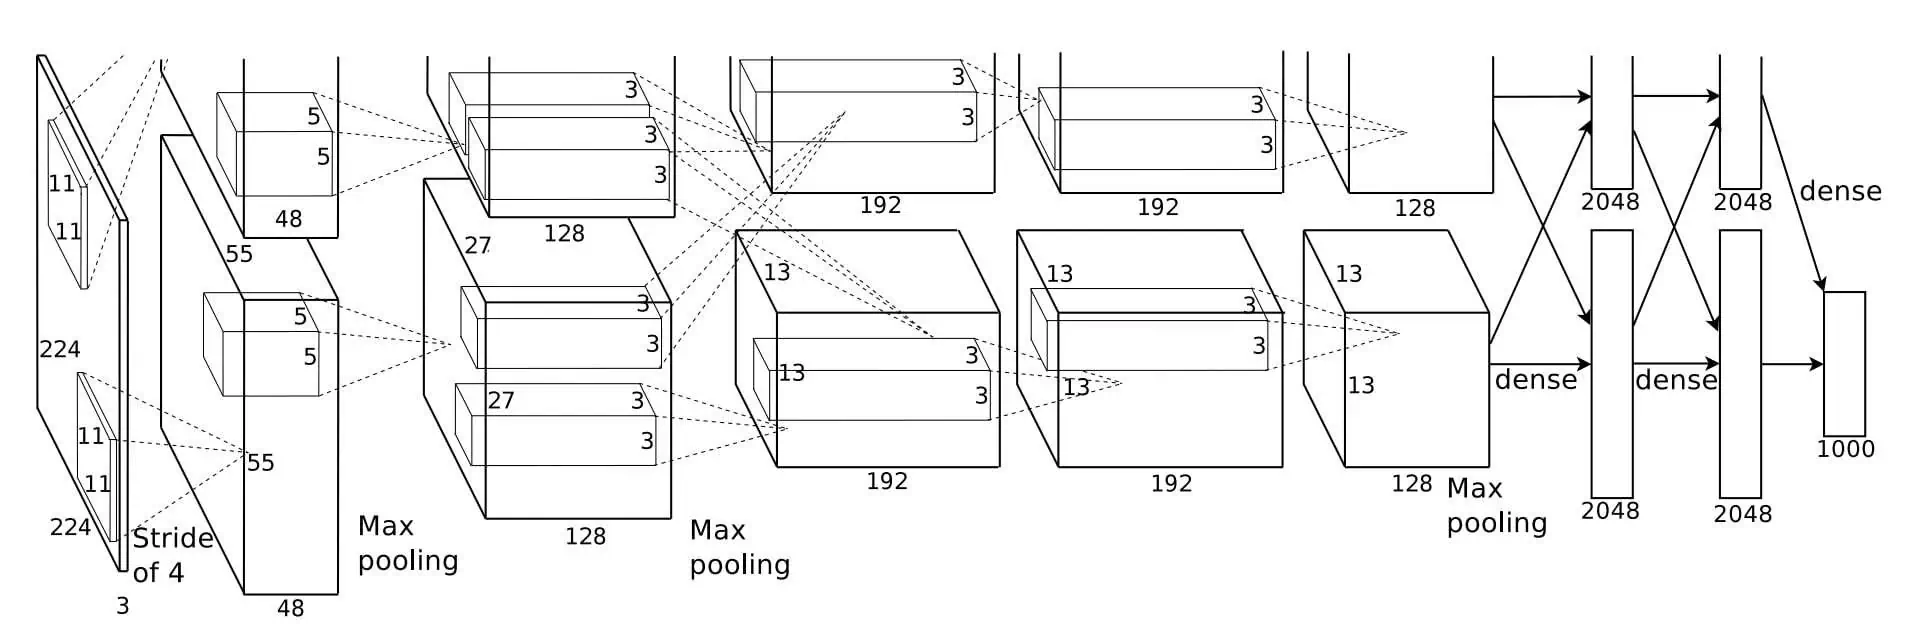

In [27]:
from PIL import Image

img = Image.open("alexnet.webp")
img

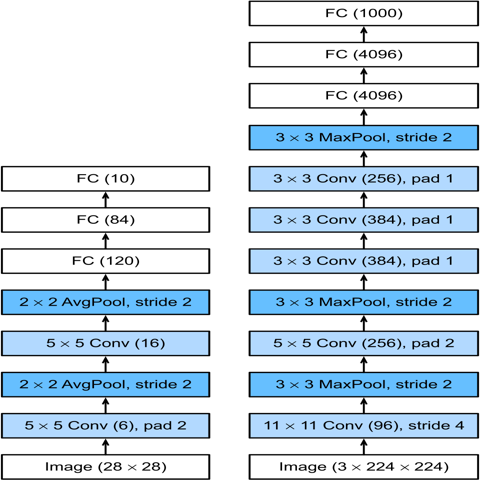

In [28]:
img = Image.open("block.webp")
img = img.resize(size=(480,480))
img


In [40]:
from typing import Any

import torch 
import torch.nn as nn

num_classes = 10

class AlexNet(nn.Module):
    def __init__(self, *args: Any, **kwargs: Any) -> None:
        super().__init__(*args, **kwargs)

        self.features = nn.Sequential(
            # input -> 227x227x3 (to kernel size 11 and stride 4)
            # nn.Conv2d(in_channels= 3, out_channels= 96, kernel_size=11, stride=4),
            nn.Conv2d(in_channels= 1, out_channels= 96, kernel_size=3, stride=1), # for MNIST datatset
            nn.ReLU(inplace=True),
            # nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2),
            # nn.MaxPool2d(kernel_size=3, stride=2),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # second layer -> 27x27x96 ( to kernel size 5 and stride 1 and padding 2)
            nn.Conv2d(in_channels=96, out_channels=256, kernel_size=5, padding=2),
            nn.ReLU(inplace=True),
            # nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2),
            # nn.MaxPool2d(kernel_size=3, stride=2),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # third layer -> 13x13x256 ( to kernel size 3 and stride padding 1)
            nn.Conv2d(in_channels=256, out_channels=384, stride=1, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),
            # nn.LocalResponseNorm(size=5, alpha=1e-4, beta=0.75, k=2), 
            # no max pooling here

            # fourth layer -> 13x13x384 ( to kernel size 3 and stride padding 1)
            nn.Conv2d(in_channels=384, out_channels=384, stride=1, kernel_size=3, padding=1),
            nn.ReLU(inplace=True),

            # fifth layer -> 13x13x384
            nn.Conv2d(in_channels=384, out_channels=256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(inplace=True),
            # nn.MaxPool2d(kernel_size=3, stride=2),
            nn.AdaptiveAvgPool2d((1,1)),

        )

        # classifier : fully connected layer
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.5),
            # nn.Linear(256*6*6, 4096),
            nn.Linear(256, 256),
            nn.ReLU(inplace=True),

            nn.Dropout(p=0.5),
            # nn.Linear(4096, 4096),
            # nn.ReLU(inplace=True),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)

        # flatten the feature maps before fully connected layers

        # x = torch.flatten(x, start_dim=1)

        x = self.classifier(x)

        return x

In [42]:
# training on MNIST dataset
from torchvision import datasets
train_dataset = datasets.MNIST(root="./datasets", train=True, download=True)
test_dataset = datasets.MNIST(root="./datasets", train=False, download=True)

In [43]:
class_names = train_dataset.classes
print("Classes: ", class_names)
print("Total number of images in training dataset : ", len(train_dataset))
print("Total number of images in testing dataset : ", len(test_dataset))

Classes:  ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
Total number of images in training dataset :  60000
Total number of images in testing dataset :  10000


In [44]:
from torchvision import transforms

train_dataset = datasets.MNIST(root="./datasets", train=True, download=False, transform=transforms.ToTensor())
test_dataset = datasets.MNIST(root="./datasets", train=False, download=False, transform=transforms.ToTensor())
imgs = torch.stack([img for img, _ in train_dataset], dim=0)

mean = imgs.mean()
std = imgs.std()
mean, std

(tensor(0.1307), tensor(0.3081))

In [45]:
mnist_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=mean, std=std),
])

# appplying this transformation to the dataset
train_dataset = datasets.MNIST(root="./datasets", train=True, download=False, transform=mnist_transform)
test_dataset = datasets.MNIST(root="./datasets", train=False, download=False, transform=mnist_transform)

In [46]:
# splitting the data
train_size = int( 0.85 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = torch.utils.data.random_split(dataset=train_dataset, lengths=[train_size, val_size])

len(train_dataset), len(val_dataset), len(test_dataset)

(51000, 9000, 10000)

In [47]:
# creating data loaders

from torch.utils.data import DataLoader

BATCH_SIZE = 16

train_dataloader = DataLoader(
    dataset=train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_dataloader = DataLoader(
    dataset=val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

test_dataloader = DataLoader(
    dataset=test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

len(train_dataloader), len(val_dataloader), len(test_dataloader)

(3188, 563, 625)

In [56]:
# loss function, optimizer and evaluation
from torchmetrics import Accuracy

alexnet = AlexNet()

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(params=alexnet.parameters(), lr=0.002)
accuracy = Accuracy(task = "multiclass", num_classes = 10)

In [53]:
# device = "cuda" if torch.cuda.is_available() else "cpu"
# accuracy = accuracy.to(device)

In [55]:
import torch
import torch.nn as nn

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = AlexNet().to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_dataloader:
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        correct += (
            outputs.argmax(dim=1) == labels
        ).sum().item()
        total += labels.size(0)

    train_loss = running_loss / total
    train_accuracy = 100 * correct / total

    # Evaluate on test data
    model.eval()
    test_correct = 0
    test_total = 0

    with torch.no_grad():
        for images, labels in test_dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            test_correct += (
                predictions == labels
            ).sum().item()
            test_total += labels.size(0)

    test_accuracy = 100 * test_correct / test_total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Test Acc: {test_accuracy:.2f}%"
    )


Epoch [1/5] Loss: 0.4516 Train Acc: 84.99% Test Acc: 96.65%
Epoch [2/5] Loss: 0.1195 Train Acc: 96.82% Test Acc: 97.86%
Epoch [3/5] Loss: 0.0898 Train Acc: 97.58% Test Acc: 97.85%
Epoch [4/5] Loss: 0.0753 Train Acc: 97.92% Test Acc: 98.09%
Epoch [5/5] Loss: 0.0649 Train Acc: 98.25% Test Acc: 98.62%
